# 10 - Model: XGBoost

**Sorumlu:** Aybüke Gökçe Yavaş

**Ödevdeki karşılığı:** 4. Makine Öğrenmesi Modelleri

In [ ]:
# KURULUM: bu hucreyi her oturumun basinda bir kez calistir.
# Repoyu Colab'e indirir; boylece src/ortak.py kullanilabilir.
import os
REPO_URL = "https://github.com/zeyneppbaran/ml-proje.git"  # TODO: kendi repo adresiniz
if not os.path.exists("/content/ml-proje"):
    !git clone {REPO_URL} /content/ml-proje
else:
    !git -C /content/ml-proje pull
%cd /content/ml-proje

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.ortak import veri_yukle, veriyi_bol, on_isleyici, degerlendir, RANDOM_STATE

df = veri_yukle()
X_train, X_test, y_train, y_test = veriyi_bol(df)
X_train.shape, X_test.shape

((32950, 20), (8238, 20))

## E1. Temel (baseline) model: varsayılan ayarlarla sonuç

In [2]:
import time
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier
from src.ortak import ortak_cv, capraz_dogrula

# 1. Temel XGBoost modeli (XGBoost'un varsayılan değerleri açıkça yazıldı)
baseline_model = Pipeline([
    ("preprocessor", on_isleyici()),
    ("classifier", XGBClassifier(n_estimators=100,
                                 learning_rate=0.3,
                                 max_depth=6,
                                 eval_metric='logloss',
                                 random_state=RANDOM_STATE))
])

# 2. 5 katlı çapraz doğrulama (sadece eğitim verisi, test setine dokunulmuyor)
t0 = time.time()
baseline_cv = capraz_dogrula(baseline_model, X_train, y_train)
baseline_sure = time.time() - t0

print("Temel Model - 5 Katlı CV Sonuçları (ortalama ± std):")
for metrik, deger in baseline_cv.items():
    print(f"{metrik:10s}: {deger['ortalama']:.4f} ± {deger['std']:.4f}")
print(f"\nCV Süresi: {baseline_sure:.2f} sn")

# 3. Sınıflandırma raporu (her örnek, eğitimde görmediği katta tahmin edilir)
y_pred_cv = cross_val_predict(baseline_model, X_train, y_train, cv=ortak_cv(), n_jobs=-1)
print("\nDoğruluk Skoru:", accuracy_score(y_train, y_pred_cv))
print("\nSınıflandırma Raporu:")
print(classification_report(y_train, y_pred_cv, target_names=['no (0)', 'yes (1)']))

Temel Model - 5 Katlı CV Sonuçları (ortalama ± std):
accuracy  : 0.8965 ± 0.0026
precision : 0.5880 ± 0.0263
recall    : 0.2737 ± 0.0079
f1        : 0.3734 ± 0.0113
roc_auc   : 0.7807 ± 0.0064

CV Süresi: 4.97 sn

Doğruluk Skoru: 0.8965098634294385

Sınıflandırma Raporu:
              precision    recall  f1-score   support

      no (0)       0.91      0.98      0.94     29238
     yes (1)       0.59      0.27      0.37      3712

    accuracy                           0.90     32950
   macro avg       0.75      0.62      0.66     32950
weighted avg       0.88      0.90      0.88     32950



**Yorum:** XGBoost varsayılan ayarlarla (100 ağaç, learning_rate=0.3, max_depth=6) eğitim verisinde 5 katlı çapraz doğrulama ile değerlendirilmiştir. Accuracy %89,7 ile yüksek görünse de dengesiz veride yanıltıcıdır: model "yes" müşterilerinin yalnızca %27'sini yakalayabilmektedir (recall 0,27). Precision'ın (0,59) recall'dan çok yüksek olması, modelin çoğunluk sınıfı olan "no"ya kaydığını gösterir. ROC-AUC 0,78, modelin sınıfları ayırt etme gücünün fena olmadığını ama karar eşiğinin dengesizlik yüzünden "no" tarafında kaldığını gösterir. E2'de hiperparametre araması ve scale_pos_weight (azınlık sınıfına ağırlık verme) ile F1 ve recall'u yükseltmeyi hedefliyoruz.

## E2. Hiperparametre araması (GridSearchCV / RandomizedSearchCV + StratifiedKFold)

In [3]:
from sklearn.model_selection import GridSearchCV

# 1. Dengesizlik oranı: scale_pos_weight için (no sayısı / yes sayısı)
dengesizlik_orani = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Eğitim verisinde no/yes oranı: {dengesizlik_orani:.2f}")

# 2. Aranacak model (ön işleme + XGBoost)
pipeline = Pipeline([
    ("preprocessor", on_isleyici()),
    ("classifier", XGBClassifier(eval_metric='logloss',
                                 random_state=RANDOM_STATE))
])

# 3. Denenecek hiperparametre değerleri (3 x 2 x 2 x 2 x 2 = 48 kombinasyon)
param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__max_depth": [3, 5],
    "classifier__subsample": [0.8, 1.0],
    "classifier__scale_pos_weight": [1, round(dengesizlik_orani, 2)]
}

# 4. GridSearchCV + StratifiedKFold(5), ana metrik F1
grid_search = GridSearchCV(pipeline,
                           param_grid,
                           scoring="f1",
                           cv=ortak_cv(),
                           n_jobs=-1,
                           return_train_score=True,
                           verbose=1)
t0 = time.time()
grid_search.fit(X_train, y_train)
grid_sure = time.time() - t0
print(f"Arama Süresi: {grid_sure:.1f} sn")

# 5. En iyi kombinasyon
print("\nEn İyi Hiperparametreler:")
for parametre, deger in grid_search.best_params_.items():
    print(f"{parametre.replace('classifier__', ''):18s}: {deger}")
print(f"\nEn İyi CV F1 Skoru: {grid_search.best_score_:.4f}")
best_model = grid_search.best_estimator_

# 6. Denenen kombinasyonlardan en iyi 10 tanesi (tablo)
sonuclar = pd.DataFrame(grid_search.cv_results_)
param_sutunlari = [c for c in sonuclar.columns if c.startswith("param_")]
tablo = sonuclar[param_sutunlari + ["mean_train_score", "mean_test_score",
                                    "std_test_score", "rank_test_score"]]
tablo.columns = ([c.replace("param_classifier__", "") for c in param_sutunlari]
                 + ["Eğitim F1", "CV F1", "CV F1 Std", "Sıra"])
print("\nEn İyi 10 Kombinasyon:")
print(tablo.sort_values("Sıra").head(10).round(4).to_string(index=False))

# scale_pos_weight etkisi: dengeleme yokken (1) ve varken (7.88) en iyi F1
print("\nscale_pos_weight değerine göre en iyi CV F1:")
print(tablo.groupby("scale_pos_weight")["CV F1"].max().round(4))

Eğitim verisinde no/yes oranı: 7.88
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Arama Süresi: 33.1 sn

En İyi Hiperparametreler:
learning_rate     : 0.05
max_depth         : 5
n_estimators      : 200
scale_pos_weight  : 7.88
subsample         : 0.8

En İyi CV F1 Skoru: 0.4688

En İyi 10 Kombinasyon:
 learning_rate  max_depth  n_estimators  scale_pos_weight  subsample  Eğitim F1  CV F1  CV F1 Std  Sıra
          0.05          5           200              7.88        0.8     0.5082 0.4688     0.0044     1
          0.05          5           300              7.88        0.8     0.5299 0.4667     0.0045     2
          0.05          5           100              7.88        0.8     0.4851 0.4665     0.0066     3
          0.10          5           100              7.88        0.8     0.5062 0.4656     0.0055     4
          0.05          5           300              7.88        1.0     0.5102 0.4643     0.0089     5
          0.05          5           200              7.88

**Yorum:** 48 kombinasyon eğitim verisinde GridSearchCV ve 5 katlı StratifiedKFold ile denenmiş, dengesiz veri nedeniyle seçim ölçütü olarak F1 kullanılmıştır. En iyi kombinasyon learning_rate=0.05, max_depth=5, n_estimators=200, subsample=0.8, scale_pos_weight=7.88 olmuş ve CV F1 temel modeldeki 0,373'ten 0,469'a yükselmiştir. İyileşmenin ana kaynağı scale_pos_weight'tir: "yes" örneklerine no/yes oranı kadar (7,88) ağırlık verildiğinde en iyi F1 0,377'den 0,469'a çıkmış, en iyi 10 kombinasyonun tamamında bu değer yer almıştır. Seçilen ayarlar varsayılana göre daha temkinlidir (küçük öğrenme oranı, sığ ağaçlar, verinin %80'iyle eğitilen ağaçlar). Eğitim F1 (0,508) ile CV F1 (0,469) arasındaki fark küçüktür; overfitting E4'te ayrıca incelenecektir.

## E3. Veri bölme yöntemi: hold-out + cross validation açıklaması

In [4]:
# 1. Hold-out: veri %80 eğitim, %20 test olarak ayrıldı (veriyi_bol, stratify=y)
print(f"Toplam veri      : {len(df)} satır")
print(f"Eğitim seti (%80): {len(X_train)} satır | 'yes' oranı: %{y_train.mean()*100:.2f}")
print(f"Test seti (%20)  : {len(X_test)} satır | 'yes' oranı: %{y_test.mean()*100:.2f}")
print(f"Özellik sayısı   : {X_train.shape[1]} (duration çıkarıldı)")

# 2. 5 katlı StratifiedKFold: her katta eğitim/doğrulama boyutu ve 'yes' oranı
print("\n5 Katlı Stratified Cross Validation (sadece eğitim verisi):")
for kat, (egitim_idx, dogrulama_idx) in enumerate(ortak_cv().split(X_train, y_train), start=1):
    print(f"Kat {kat}: eğitim {len(egitim_idx)} satır, doğrulama {len(dogrulama_idx)} satır | "
          f"doğrulamada 'yes' oranı: %{y_train.iloc[dogrulama_idx].mean()*100:.2f}")

Toplam veri      : 41188 satır
Eğitim seti (%80): 32950 satır | 'yes' oranı: %11.27
Test seti (%20)  : 8238 satır | 'yes' oranı: %11.26
Özellik sayısı   : 20 (duration çıkarıldı)

5 Katlı Stratified Cross Validation (sadece eğitim verisi):
Kat 1: eğitim 26360 satır, doğrulama 6590 satır | doğrulamada 'yes' oranı: %11.26
Kat 2: eğitim 26360 satır, doğrulama 6590 satır | doğrulamada 'yes' oranı: %11.26
Kat 3: eğitim 26360 satır, doğrulama 6590 satır | doğrulamada 'yes' oranı: %11.26
Kat 4: eğitim 26360 satır, doğrulama 6590 satır | doğrulamada 'yes' oranı: %11.27
Kat 5: eğitim 26360 satır, doğrulama 6590 satır | doğrulamada 'yes' oranı: %11.27


**Yorum:** Veri iki aşamada bölünmüştür. İlk olarak hold-out yöntemiyle %80 eğitim (32.950 satır) ve %20 test (8.238 satır) olarak ayrılmıştır (stratify=y, random_state=42). Test seti en başta kilitlenmiş ve yalnızca E5'teki nihai değerlendirmede bir kez kullanılacaktır. Model ve hiperparametre seçimi tamamen eğitim verisi içinde, 5 katlı StratifiedKFold ile yapılmıştır: eğitim verisi 5 parçaya bölünür, her turda 4 parça (26.360 satır) eğitim ve 1 parça (6.590 satır) doğrulama için kullanılır, 5 skorun ortalaması alınır. "Stratified" bölme sayesinde "yes" oranı test setinde ve her katta %11,3 olarak korunmuştur. Ön işleme Pipeline içinde olduğu için her katta yalnızca o katın eğitim kısmından öğrenilmiş, veri sızıntısı önlenmiştir.

## E4. Overfitting analizi (eğitim/doğrulama skoru, learning curve) ve alınan önlem

            Model  Metrik  Eğitim Skoru  Doğrulama Skoru   Fark
 Temel Model (E1)      f1        0.6034           0.3734 0.2299
 Temel Model (E1) roc_auc        0.9189           0.7807 0.1382
En İyi Model (E2)      f1        0.5082           0.4688 0.0395
En İyi Model (E2) roc_auc        0.8722           0.7949 0.0773


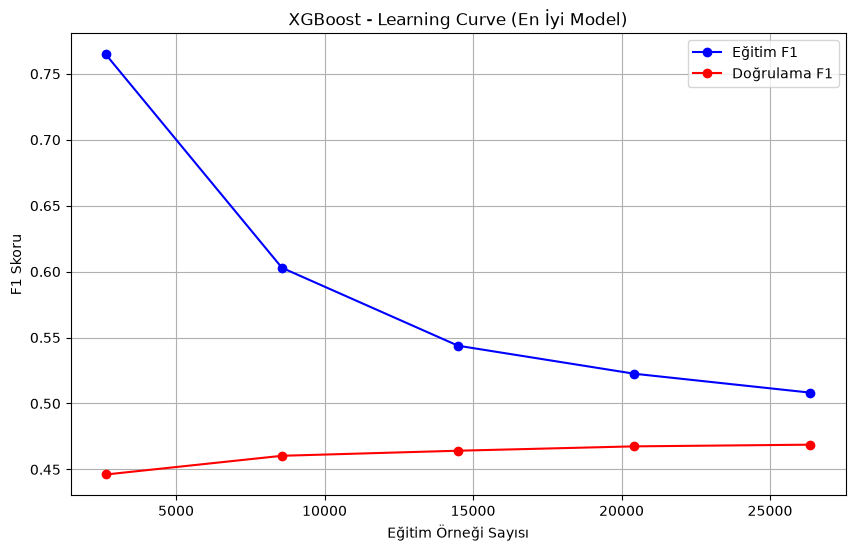

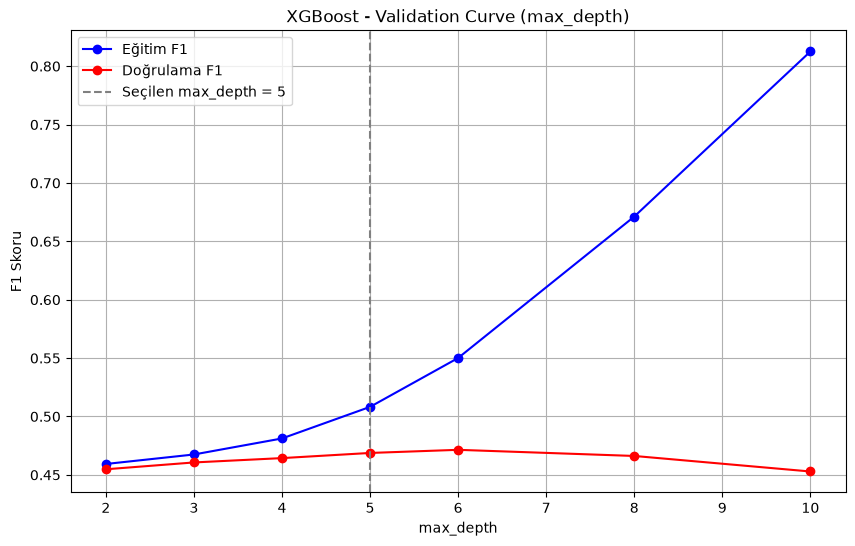

max_depth= 2 -> Eğitim F1: 0.4593, Doğrulama F1: 0.4548, Fark: 0.0045
max_depth= 3 -> Eğitim F1: 0.4675, Doğrulama F1: 0.4606, Fark: 0.0068
max_depth= 4 -> Eğitim F1: 0.4812, Doğrulama F1: 0.4644, Fark: 0.0168
max_depth= 5 -> Eğitim F1: 0.5082, Doğrulama F1: 0.4688, Fark: 0.0395
max_depth= 6 -> Eğitim F1: 0.5501, Doğrulama F1: 0.4715, Fark: 0.0786
max_depth= 8 -> Eğitim F1: 0.6712, Doğrulama F1: 0.4662, Fark: 0.2050
max_depth=10 -> Eğitim F1: 0.8126, Doğrulama F1: 0.4529, Fark: 0.3597


In [5]:
from sklearn.model_selection import cross_validate, learning_curve, validation_curve

# 1. Eğitim ve doğrulama skorlarının karşılaştırılması (önce / sonra)
karsilastirma = []
for model_adi, model in [("Temel Model (E1)", baseline_model), ("En İyi Model (E2)", best_model)]:
    sonuc = cross_validate(model, X_train, y_train, cv=ortak_cv(),
                           scoring=["f1", "roc_auc"], return_train_score=True, n_jobs=-1)
    for metrik in ["f1", "roc_auc"]:
        egitim = sonuc[f"train_{metrik}"].mean()
        dogrulama = sonuc[f"test_{metrik}"].mean()
        karsilastirma.append([model_adi, metrik, egitim, dogrulama, egitim - dogrulama])

karsilastirma_df = pd.DataFrame(karsilastirma, columns=["Model", "Metrik", "Eğitim Skoru",
                                                        "Doğrulama Skoru", "Fark"])
print(karsilastirma_df.round(4).to_string(index=False))

# 2. Learning curve (en iyi model)
egitim_boyutlari, egitim_skorlari, dogrulama_skorlari = learning_curve(
    best_model, X_train, y_train, cv=ortak_cv(), scoring="f1",
    train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=-1)

plt.figure(figsize=(10, 6))
plt.plot(egitim_boyutlari, egitim_skorlari.mean(axis=1), 'o-', color='blue', label='Eğitim F1')
plt.plot(egitim_boyutlari, dogrulama_skorlari.mean(axis=1), 'o-', color='red', label='Doğrulama F1')
plt.title("XGBoost - Learning Curve (En İyi Model)")
plt.xlabel("Eğitim Örneği Sayısı")
plt.ylabel("F1 Skoru")
plt.legend()
plt.grid(True)
plt.savefig("figures/e4_xgboost_learning_curve.png", dpi=150, bbox_inches='tight')
plt.show()

# 3. Validation curve: max_depth arttıkça eğitim ve doğrulama skoru nasıl değişiyor?
derinlikler = [2, 3, 4, 5, 6, 8, 10]
egitim_skorlari, dogrulama_skorlari = validation_curve(
    best_model, X_train, y_train, param_name="classifier__max_depth",
    param_range=derinlikler, cv=ortak_cv(), scoring="f1", n_jobs=-1)

plt.figure(figsize=(10, 6))
plt.plot(derinlikler, egitim_skorlari.mean(axis=1), 'o-', color='blue', label='Eğitim F1')
plt.plot(derinlikler, dogrulama_skorlari.mean(axis=1), 'o-', color='red', label='Doğrulama F1')
plt.axvline(5, color='gray', linestyle='--', label='Seçilen max_depth = 5')
plt.title("XGBoost - Validation Curve (max_depth)")
plt.xlabel("max_depth")
plt.ylabel("F1 Skoru")
plt.legend()
plt.grid(True)
plt.savefig("figures/e4_xgboost_validation_curve.png", dpi=150, bbox_inches='tight')
plt.show()

for d, e, v in zip(derinlikler, egitim_skorlari.mean(axis=1), dogrulama_skorlari.mean(axis=1)):
    print(f"max_depth={d:2d} -> Eğitim F1: {e:.4f}, Doğrulama F1: {v:.4f}, Fark: {e - v:.4f}")

**Yorum:** Temel modelde belirgin bir overfitting vardır: eğitim F1 0,603, doğrulama F1 0,373 (fark 0,23). Varsayılan ayarlar (learning_rate=0.3, max_depth=6) modelin eğitim verisini ezberlemesine yol açmıştır. Önlem olarak E2'de öğrenme oranı küçültülmüş (0.05), ağaç derinliği sınırlanmış (max_depth=5) ve her ağacın verinin %80'iyle eğitilmesi sağlanmıştır (subsample=0.8). Bu önlemlerle fark 0,04'e düşerken doğrulama F1 0,469'a yükselmiştir. Learning curve'de iki eğri veri arttıkça birbirine yaklaşmakta, doğrulama eğrisi sonda düzleşmektedir; bu da modelin dengeli öğrendiğini gösterir. Validation curve'de derinlik arttıkça eğitim skoru sürekli yükselirken doğrulama skoru 5-6 civarında zirve yapıp düşmektedir (max_depth=10'da fark 0,36). max_depth=6 doğrulamada çok az daha yüksek skor (0,4715) verse de farkı iki katına (0,079) çıkardığı için max_depth=5 korunmuştur.

## E5. Test seti sonuçları: confusion matrix, precision, recall, F1, ROC-AUC, ROC eğrisi

--- xgboost Test Performansı ---
model       : xgboost
accuracy    : 0.8491
precision   : 0.3971
recall      : 0.6552
f1          : 0.4945
roc_auc     : 0.8145

Doğruluk Skoru: 0.8491138625880068

Sınıflandırma Raporu:
              precision    recall  f1-score   support

      no (0)       0.95      0.87      0.91      7310
     yes (1)       0.40      0.66      0.49       928

    accuracy                           0.85      8238
   macro avg       0.67      0.76      0.70      8238
weighted avg       0.89      0.85      0.86      8238



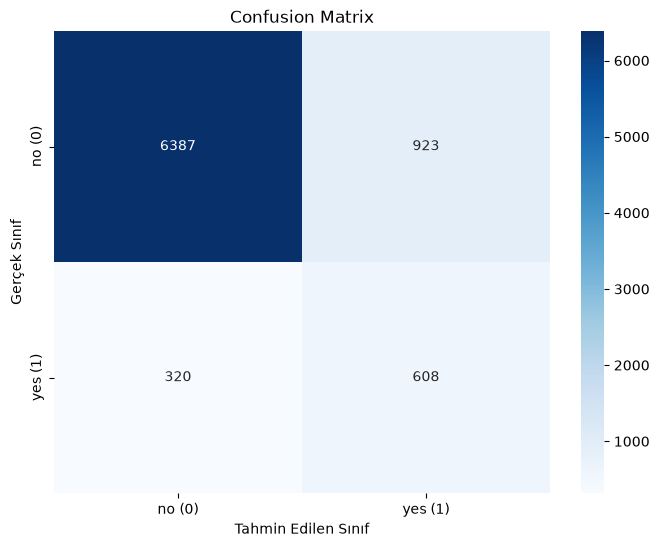

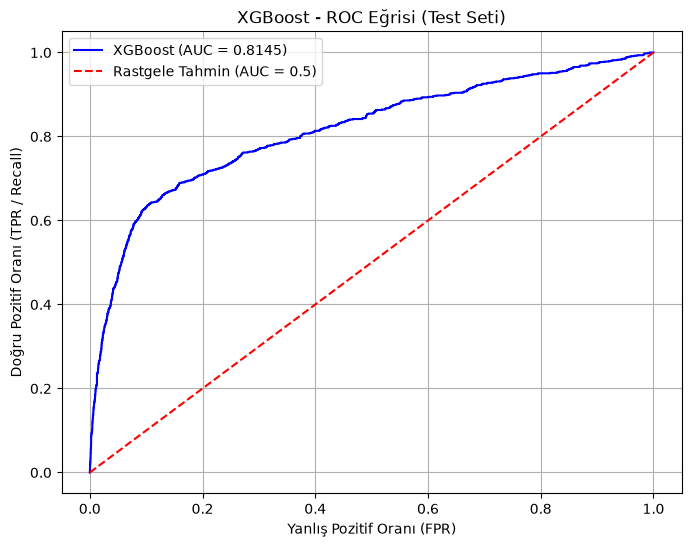

In [6]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

# 1. Test seti üzerinde tahmin (test seti ilk ve tek kez burada kullanılıyor)
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]  # 'yes' olma olasılığı

# 2. Ortak değerlendirme fonksiyonu: metrikleri yazdırır ve results/xgboost.json olarak kaydeder
sonuc = degerlendir(best_model, X_test, y_test, "xgboost")

print("\nDoğruluk Skoru:", accuracy_score(y_test, y_pred))
print("\nSınıflandırma Raporu:")
print(classification_report(y_test, y_pred, target_names=['no (0)', 'yes (1)']))

# 3. Confusion Matrix oluşturma ve görselleştirme
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True,
            fmt='d', cmap='Blues',
            xticklabels=['no (0)', 'yes (1)'],
            yticklabels=['no (0)', 'yes (1)'])
plt.title("Confusion Matrix")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")
plt.savefig("figures/e5_xgboost_confusion_matrix.png", dpi=150, bbox_inches='tight')
plt.show()

# 4. ROC eğrisi
fpr, tpr, esikler = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'XGBoost (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Rastgele Tahmin (AUC = 0.5)')
plt.title("XGBoost - ROC Eğrisi (Test Seti)")
plt.xlabel("Yanlış Pozitif Oranı (FPR)")
plt.ylabel("Doğru Pozitif Oranı (TPR / Recall)")
plt.legend()
plt.grid(True)
plt.savefig("figures/e5_xgboost_roc_egrisi.png", dpi=150, bbox_inches='tight')
plt.show()

**Yorum:** En iyi model, ilk kez kullanılan test setinde (8.238 müşteri) F1 = 0,495, recall = 0,655 ve ROC-AUC = 0,815 elde etmiştir. Test sonuçları CV sonuçlarıyla tutarlıdır (CV F1 0,469, CV ROC-AUC 0,795); yani model görmediği veride de benzer başarı gösteriyor. Confusion matrix'e göre 928 gerçek "yes" müşterisinin 608'i (%65,5) doğru yakalanmıştır; temel modelde bu oran %27 idi. Bunun bedeli precision'ın 0,40'a inmesidir: model "yes" dediği her 10 müşteriden yaklaşık 4'ünde haklıdır (923 yanlış pozitif). Banka açısından boşa bir telefon araması, kaçırılan bir müşteriden daha ucuz olduğu için bu denge kabul edilebilirdir. Accuracy'nin 0,897'den 0,849'a düşmesi beklenen bir sonuçtur, çünkü model artık her müşteriye "no" demeye eğilimli değildir.

## E6. Bu modelin avantajları ve dezavantajları

In [7]:
from sklearn.base import clone

# 1. Eğitim süresi: en iyi ayarlarla tüm eğitim verisinde (32.950 satır) bir kez eğitim
model_kopya = clone(best_model)
t0 = time.time()
model_kopya.fit(X_train, y_train)
egitim_suresi = time.time() - t0

# 2. Tahmin süresi (test seti E5'te bir kez kullanıldı; ölçüm eğitim verisiyle yapılır)
t1 = time.time()
_ = model_kopya.predict(X_train.iloc[:5000])
tahmin_suresi = time.time() - t1

# 3. Süre tablosu
sure_tablosu = pd.DataFrame([
    ["Temel model 5 katlı CV (E1)", baseline_sure],
    ["GridSearchCV, 48 kombinasyon x 5 kat (E2)", grid_sure],
    ["En iyi model tek eğitim (32.950 satır)", egitim_suresi],
    ["Tahmin (5.000 satır)", tahmin_suresi]
], columns=["İşlem", "Süre (sn)"])
print(sure_tablosu.round(3).to_string(index=False))
print(f"\nModelin gördüğü özellik sayısı (One-Hot sonrası): {model_kopya.named_steps['classifier'].n_features_in_}")

                                    İşlem  Süre (sn)
              Temel model 5 katlı CV (E1)      4.975
GridSearchCV, 48 kombinasyon x 5 kat (E2)     33.058
   En iyi model tek eğitim (32.950 satır)      0.356
                     Tahmin (5.000 satır)      0.020

Modelin gördüğü özellik sayısı (One-Hot sonrası): 58


**Yorum:** Avantajlar:

Bu veri setinde güçlü sonuç verdi: test F1 0,495, ROC-AUC 0,815 (lojistik regresyon: 0,467 / 0,801).
Doğrusal olmayan ilişkileri ve özellikler arası etkileşimleri kendisi yakalar.
Dengesiz veri için hazır ayarı vardır (scale_pos_weight); SMOTE ile sentetik veri üretmeye gerek kalmadı.
Ölçekleme gerektirmez; aykırı değerlerden ve birbirine çok bağlı sütunlardan (C4'teki ekonomik göstergeler) az etkilenir.
Hızlıdır: tek eğitim 1 saniyenin altında, tahmin neredeyse anlık.
Yerleşik düzenlileştirme parametreleriyle overfitting kontrol edilebilir (E4'te fark 0,23'ten 0,04'e indi).

Dezavantajlar:

Ayarlanacak çok hiperparametre vardır; varsayılan ayarlarla overfit etti, bu yüzden arama şarttır.
Arama süresi kombinasyon sayısıyla hızla artar (48 kombinasyon × 5 kat = 240 eğitim).
Lojistik regresyon gibi doğrudan yorumlanabilir katsayı vermez; neden öyle karar verdiğini açıklamak için SHAP gibi ek yöntemler gerekir.
Ağaçlar sırayla kurulduğu için Random Forest gibi tam paralel eğitilemez.
Recall'u artırmanın bedeli olarak precision düşük kaldı (0,40).

## Modelin kaydedilmesi (joblib)

In [8]:
import os
import joblib

# 1. Modellerin kaydedileceği klasör (yoksa oluşturulur)
os.makedirs("models", exist_ok=True)
model_yolu = "models/xgboost_best_model.joblib"

# 2. En iyi modelin (ön işleme + XGBoost Pipeline'ı) kaydedilmesi
joblib.dump(best_model, model_yolu)
print(f"Model kaydedildi: {model_yolu}")

# 3. Kontrol: kaydedilen modeli geri yükleyip E5'teki tahminlerle karşılaştırma
yuklenen_model = joblib.load(model_yolu)
ayni_mi = (yuklenen_model.predict(X_test) == y_pred).all()
print(f"Yüklenen model aynı tahminleri veriyor mu? {ayni_mi}")

Model kaydedildi: models/xgboost_best_model.joblib
Yüklenen model aynı tahminleri veriyor mu? True
